# EDA de metadatos y partición

Este notebook trabaja sobre el conjunto completo de HAM10000: integridad de los archivos,
búsqueda de duplicados por pHash, análisis de los metadatos y generación de la partición
agrupada. Todos los parámetros se leen de `configs/base.yaml`.

## 1. Configuración

Se cargan la configuración y las funciones de `src/`, y se fija la semilla global.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src import data, eda, stats
from src.utils import set_seed

2026-11-13 12:47:47.281432: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
cfg = data.load_config()
set_seed(cfg["seed"])
rutas = cfg["paths"]

## 2. Integridad

Número de filas e imágenes, correspondencia entre `image_id` y archivos, imágenes que no
se pueden abrir y SHA-256 de los archivos descargados.

In [3]:
meta = data.load_metadata(cfg)
display(pd.Series({"filas": meta.shape[0], "columnas": meta.shape[1]}, name="valor").to_frame())
meta.head()

,valor
filas,10015
columnas,8


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [4]:
integridad = data.check_integrity(meta, cfg)
pd.Series({k: len(v) if isinstance(v, list) else v for k, v in integridad.items()}, name="valor").to_frame()

,valor
n_filas,10015
n_image_id_unicos,10015
n_lesion_id_unicos,7470
n_archivos_imagen,10015
image_id_repetidos,0
image_id_sin_archivo,0
archivos_sin_image_id,0


Imágenes que `PIL.Image.verify` no puede leer.

In [5]:
rutas_img = [p for p in data.image_paths(cfg, meta["image_id"]) if p.exists()]
ilegibles = data.find_unreadable_images(rutas_img)
display(pd.Series({"imágenes no legibles": len(ilegibles)}, name="valor").to_frame())
ilegibles

Verificando imágenes: 100%|██████████| 10015/10015 [00:00<00:00, 29881.99it/s]


,valor
imágenes no legibles,0


,ruta,error


SHA-256 de los `.zip` del primer nivel de `data/raw/` y del CSV de metadatos. Si
`data/hashes.json` no existe, se crea; si existe, no se modifica y se compara con los
valores actuales.

In [6]:
hashes = data.raw_file_hashes(cfg)
data.record_hashes(hashes, rutas["hashes_json"])

SHA-256: 100%|██████████| 4/4 [00:03<00:00,  1.08it/s]


,sha256_actual,sha256_registrado,coincide
archivo,,,
data/raw/HAM10000_images_part_1.zip,6202a599129c2efe81c25aea8586d422eeda8a4fae5df4...,6202a599129c2efe81c25aea8586d422eeda8a4fae5df4...,True
data/raw/HAM10000_images_part_2.zip,9677f30118c21ecc667a147de369d89acb25efab046fd3...,9677f30118c21ecc667a147de369d89acb25efab046fd3...,True
data/raw/HAM10000_metadata.csv,de17ec44cb25ea9c3f6378ba18d69224c740afd62e86ec...,de17ec44cb25ea9c3f6378ba18d69224c740afd62e86ec...,True
data/raw/HAM10000_segmentations_lesion_tschandl.zip,6d88d7df8cc806c938932939d50c17fb9ad206c143343e...,6d88d7df8cc806c938932939d50c17fb9ad206c143343e...,True


### Calidad de los metadatos

Valores de edad fuera de rango, categorías que no están en las listas de
`valid_categories` y valores distintos dentro de un mismo `lesion_id`. Solo se marcan
casos; no se modifica ningún dato.

#### Edad fuera de rango

Edad igual a 0 o fuera de [`age_min_valid`, `age_max_valid`].

In [7]:
resumen_edad, filas_edad = eda.age_out_of_range(meta, cfg["age_min_valid"], cfg["age_max_valid"])
display(resumen_edad)
filas_edad

,filas
edad = 0,39
edad < 1 (distinta de 0),0
edad > 100,0


,image_id,lesion_id,age,sex,localization,dx,dataset,motivo
0,ISIC_0025906,HAM_0007179,0.0,female,back,bkl,vidir_modern,edad = 0
1,ISIC_0027151,HAM_0007179,0.0,female,back,bkl,vidir_modern,edad = 0
2,ISIC_0029320,HAM_0006186,0.0,male,lower extremity,bkl,vidir_modern,edad = 0
3,ISIC_0029427,HAM_0006186,0.0,male,lower extremity,bkl,vidir_modern,edad = 0
4,ISIC_0032170,HAM_0004543,0.0,female,back,bkl,vidir_modern,edad = 0
5,ISIC_0026876,HAM_0002610,0.0,female,abdomen,vasc,vidir_modern,edad = 0
6,ISIC_0030606,HAM_0002610,0.0,female,abdomen,vasc,vidir_modern,edad = 0
7,ISIC_0024402,HAM_0004542,0.0,female,back,vasc,vidir_modern,edad = 0
8,ISIC_0027256,HAM_0004542,0.0,female,back,vasc,vidir_modern,edad = 0
9,ISIC_0029049,HAM_0003246,0.0,male,ear,nv,vidir_modern,edad = 0


#### Categorías

Valores únicos de cada columna de `valid_categories`; `valido` es falso si el valor no está en la lista.

In [8]:
categorias = eda.category_check(meta, cfg["valid_categories"])
display(categorias.groupby("columna")["valido"].agg(valores_unicos="size", fuera_de_lista=lambda s: int((~s).sum())))
categorias

,valores_unicos,fuera_de_lista
columna,,
dataset,4,0
dx,7,0
dx_type,4,0
localization,15,0
sex,3,0


,columna,valor,n,valido
0,sex,male,5406,True
1,sex,female,4552,True
2,sex,unknown,57,True
3,localization,back,2192,True
4,localization,lower extremity,2077,True
5,localization,trunk,1404,True
6,localization,upper extremity,1118,True
7,localization,abdomen,1022,True
8,localization,face,745,True
9,localization,chest,407,True


#### Consistencia dentro de cada lesion_id

Lesiones cuyas imágenes tienen más de un valor en alguna columna de
`lesion_consistency_columns` (el vacío cuenta como valor). Se muestran hasta
`eda_inconsistency_examples` ejemplos.

In [9]:
conteo_inc, ejemplos_inc = eda.lesion_inconsistencies(meta, cfg["lesion_consistency_columns"])
display(conteo_inc)
ejemplos_inc.head(cfg["eda_inconsistency_examples"])

,lesiones inconsistentes,lesiones con más de una imagen
age,0,1956
sex,0,1956
localization,2,1956
dx_type,0,1956
dataset,9,1956


,lesion_id,columna,n_imagenes,valores
0,HAM_0000871,localization,3,chest | trunk
1,HAM_0001726,localization,3,back | trunk
2,HAM_0000492,dataset,3,vidir_modern | vidir_molemax
3,HAM_0000871,dataset,3,vidir_modern | vidir_molemax
4,HAM_0001726,dataset,3,vidir_modern | vidir_molemax
5,HAM_0002534,dataset,3,vidir_modern | vidir_molemax
6,HAM_0003194,dataset,2,vidir_modern | vidir_molemax
7,HAM_0003558,dataset,3,vidir_modern | vidir_molemax
8,HAM_0004979,dataset,3,vidir_modern | vidir_molemax
9,HAM_0005481,dataset,3,vidir_modern | vidir_molemax


## 3. Duplicados

pHash de cada imagen y distancias de Hamming entre imágenes. El umbral `phash_threshold`
se elige después de ver la distribución de distancias. Este análisis se hace antes de
partir los datos.

### 3.1 pHash de todas las imágenes

Se reutiliza `data/interim/phash.csv` si ya existe.

In [10]:
phash_df = data.load_or_compute_phash(cfg, meta)
phash_df.head()

pHash reutilizado desde /var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/data/interim/phash.csv


,image_id,phash
0,ISIC_0027419,c631cb4a3a2c4ddb
1,ISIC_0025030,c42d55ac55b406fb
2,ISIC_0026769,c3661d346466679b
3,ISIC_0025661,c5aa51bd474c12b7
4,ISIC_0031633,bc34d2c2c9c3c9cd


### 3.2 Distribución de distancias

Conteo de todos los pares de imágenes por distancia de Hamming, de 0 a `phash_dist_max`,
separando los pares con el mismo `lesion_id` y los pares con `lesion_id` distinto; para
estos últimos, también cuántos tienen además `dx` distinto. No se aplica ningún umbral.

In [11]:
dist_pares = data.distance_distribution(meta, phash_df, cfg["phash_dist_max"])
dist_pares

,pares_mismo_lesion_id,pares_lesion_id_distinto,pares_lesion_id_distinto_dx_distinto
distancia,,,
0,18,1,0
1,0,0,0
2,45,32,6
3,0,0,0
4,49,280,57
5,0,0,0
6,44,1221,229
7,0,0,0
8,33,4087,915


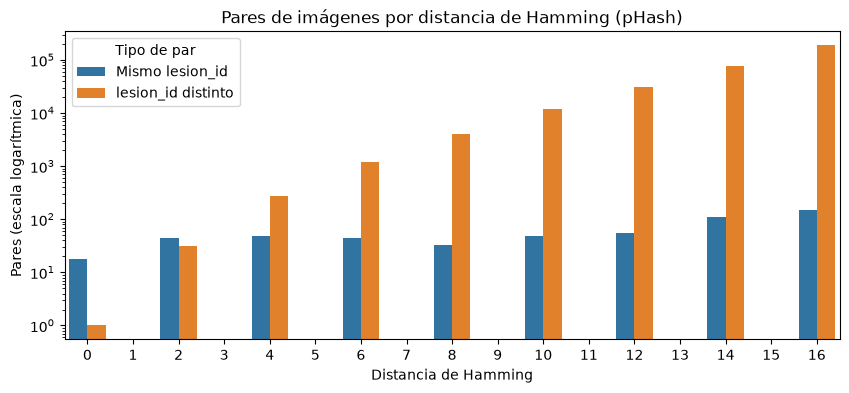

In [12]:
nombres = {"pares_mismo_lesion_id": "Mismo lesion_id", "pares_lesion_id_distinto": "lesion_id distinto"}
largo = (dist_pares[list(nombres)].rename(columns=nombres).reset_index()
         .melt(id_vars="distancia", var_name="Tipo de par", value_name="pares"))
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=largo, x="distancia", y="pares", hue="Tipo de par", ax=ax)
ax.set_yscale("log")
ax.set_title("Pares de imágenes por distancia de Hamming (pHash)")
ax.set_xlabel("Distancia de Hamming")
ax.set_ylabel("Pares (escala logarítmica)")
plt.show()

### 3.3 Elección del umbral

Elige el umbral a partir de la tabla y el gráfico anteriores, escríbelo en
`phash_threshold` de `configs/base.yaml` y ejecuta desde la celda siguiente.

### 3.4 Umbral

In [13]:
cfg = data.load_config()
umbral = cfg["phash_threshold"]
pd.Series({"phash_threshold": umbral}, name="valor").to_frame()

,valor
phash_threshold,2


### 3.5 Candidatos a duplicado entre lesiones distintas

Pares con `lesion_id` distinto y distancia menor o igual que `phash_threshold`, ordenados
por distancia de menor a mayor. Se guardan en `data/duplicados_candidatos.csv` con la
columna `confirmado` vacía.

In [14]:
candidatos = (data.duplicate_candidates(meta, phash_df, umbral)
              .sort_values("distancia", kind="stable").reset_index(drop=True))
candidatos.to_csv(rutas["duplicates_candidates_csv"], index=False)
display(pd.Series({"pares candidatos": len(candidatos), "archivo": str(rutas["duplicates_candidates_csv"])},
                  name="valor").to_frame())
candidatos

,valor
pares candidatos,33
archivo,/var/home/luencaro/Programing/College/2026-30/...


,image_id_a,image_id_b,lesion_id_a,lesion_id_b,dx_a,dx_b,distancia,confirmado
0,ISIC_0032228,ISIC_0033598,HAM_0003984,HAM_0005496,nv,nv,0,<NA>
1,ISIC_0024404,ISIC_0032183,HAM_0005076,HAM_0007351,nv,nv,2,<NA>
2,ISIC_0024437,ISIC_0032612,HAM_0002566,HAM_0000402,nv,nv,2,<NA>
3,ISIC_0025000,ISIC_0028963,HAM_0001643,HAM_0002423,nv,nv,2,<NA>
4,ISIC_0025201,ISIC_0028047,HAM_0000377,HAM_0002621,nv,nv,2,<NA>
5,ISIC_0025226,ISIC_0030074,HAM_0004919,HAM_0000140,nv,nv,2,<NA>
6,ISIC_0025375,ISIC_0026819,HAM_0007600,HAM_0007112,nv,nv,2,<NA>
7,ISIC_0025713,ISIC_0033018,HAM_0003178,HAM_0007415,nv,nv,2,<NA>
8,ISIC_0025816,ISIC_0028272,HAM_0007122,HAM_0001306,nv,nv,2,<NA>
9,ISIC_0026116,ISIC_0030556,HAM_0002855,HAM_0001771,nv,nv,2,<NA>


Revisión visual de todos los candidatos en el mismo orden (distancia de menor a mayor),
en páginas de `eda_pairs_page_size` pares, con `eda_pairs_pages_per_figure` páginas una al
lado de la otra.

,valor
pares,33
figuras,1


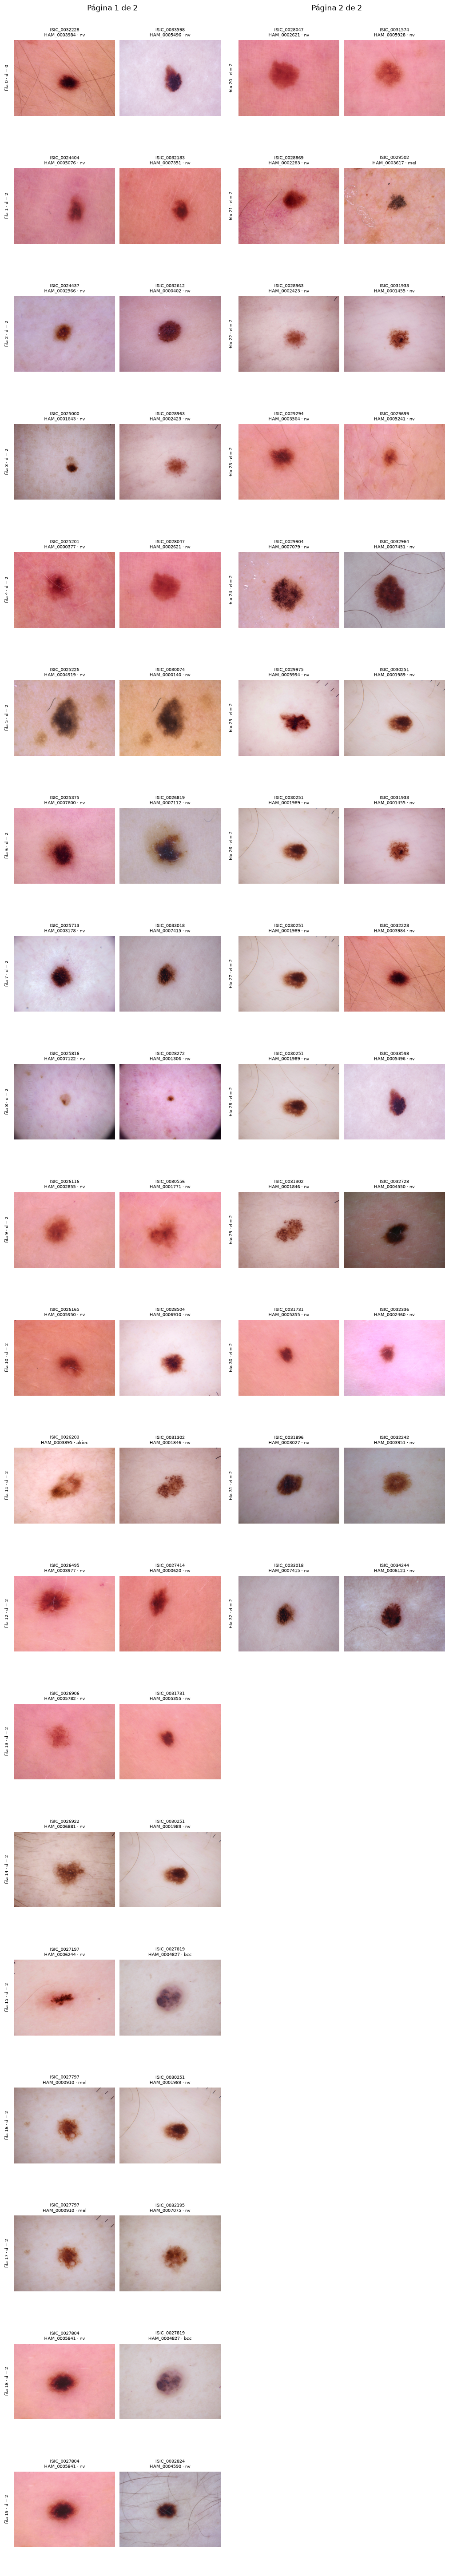

In [15]:
c = candidatos
figs = eda.plot_pair_pages(
    data.image_paths(cfg, c["image_id_a"]),
    data.image_paths(cfg, c["image_id_b"]),
    c["image_id_a"] + "\n" + c["lesion_id_a"] + " · " + c["dx_a"],
    c["image_id_b"] + "\n" + c["lesion_id_b"] + " · " + c["dx_b"],
    "fila " + c.index.to_series().astype(str) + " · d = " + c["distancia"].astype(str),
    page_size=cfg["eda_pairs_page_size"],
    pages_per_figure=cfg["eda_pairs_pages_per_figure"],
)
display(pd.Series({"pares": len(c), "figuras": len(figs)}, name="valor").to_frame())
plt.show()

### 3.6 Duplicados confirmados

La partición usa `data/duplicados_confirmados.csv` (mismas columnas que los candidatos,
con `confirmado` = 1 o 0) si existe. Si no existe, agrupa solo por `lesion_id`.

In [16]:
confirmados = data.load_confirmed_duplicates(rutas["duplicates_confirmed_csv"])
if confirmados is None:
    aviso = (f"No existe {rutas['duplicates_confirmed_csv']}. "
             "La partición se agrupará SOLO por lesion_id.")
    warnings.warn(aviso, stacklevel=1)
    display(pd.DataFrame({"advertencia": [aviso]}))
else:
    display(pd.Series({"pares confirmados (confirmado = 1)": len(confirmados)}, name="valor").to_frame())
    display(confirmados)

,valor
pares confirmados (confirmado = 1),0


,image_id_a,image_id_b,lesion_id_a,lesion_id_b,dx_a,dx_b,distancia,confirmado


## 4. Metadatos

4.A análisis univariado de cada variable; 4.B relación de cada variable con `dx`; 4.C
relación entre covariables.

In [17]:
meta_na = data.mark_missing(meta, cfg["missing_tokens"])
orden_dx = meta["dx"].value_counts().index.tolist()
tiene_fuente = data.has_source_column(meta, cfg)
fuente = cfg["source_column"]

### 4.A Univariado

Distribución de cada variable por separado.

#### dx

In [18]:
conteo_dx = stats.value_counts_pct(meta["dx"])
razon = conteo_dx["n"].max() / conteo_dx["n"].min()
display(pd.Series({"razón de desbalance (mayoritaria / minoritaria)": round(razon, 2)}, name="valor").to_frame())
conteo_dx

,valor
razón de desbalance (mayoritaria / minoritaria),58.3


,n,porcentaje
dx,,
nv,6705,66.949576
mel,1113,11.113330
bkl,1099,10.973540
bcc,514,5.132302
akiec,327,3.265102
vasc,142,1.417873
df,115,1.148278


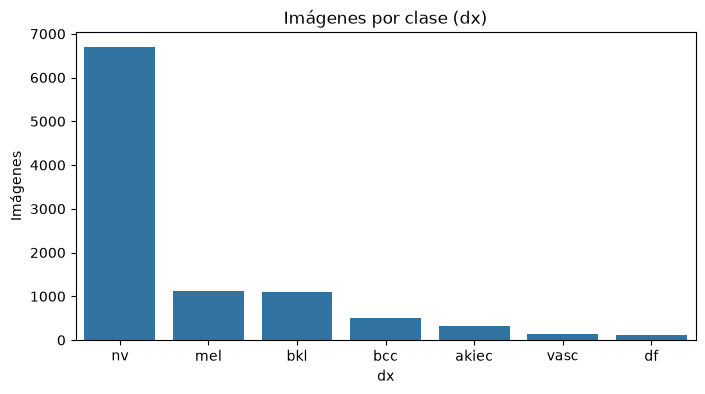

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=conteo_dx.index, y=conteo_dx["n"], order=orden_dx, ax=ax)
ax.set_title("Imágenes por clase (dx)")
ax.set_xlabel("dx")
ax.set_ylabel("Imágenes")
plt.show()

Entropía de Shannon de la distribución de `dx` en bits, entropía máxima log2(k) con k clases y entropía normalizada (entropía / máxima).

In [20]:
pd.Series(stats.class_entropy(conteo_dx["n"]), name="valor").to_frame()

,valor
clases,7.000000
entropia_bits,1.631746
entropia_maxima_bits,2.807355
entropia_normalizada,0.581240


#### Edad

In [21]:
stats.univariate_summary(meta_na, ["age"])

,faltantes,count,mean,std,min,25%,50%,75%,max,asimetria
age,57,9958.0,51.863828,16.968614,0.0,40.0,50.0,65.0,85.0,-0.166802


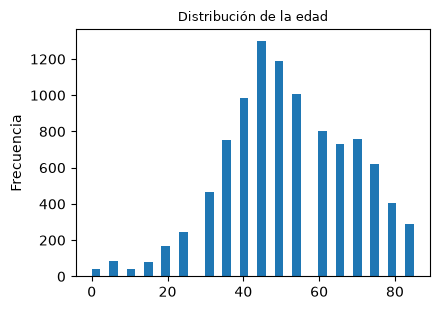

In [22]:
eda.plot_histograms(meta_na, ["age"], cfg["eda_hist_bins"], titles={"age": "Distribución de la edad"})
plt.show()

#### Sexo

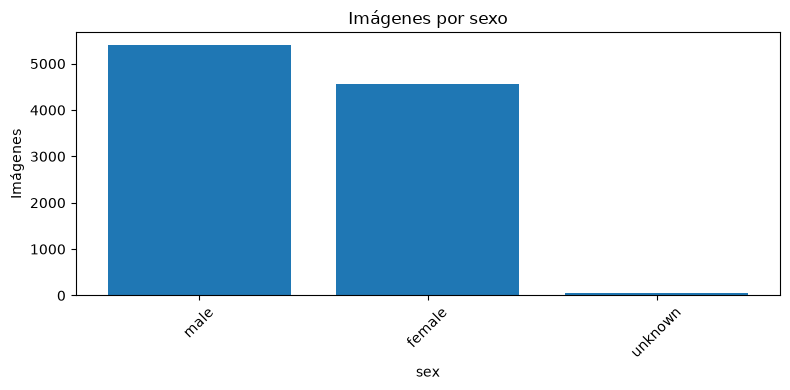

,n,porcentaje
sex,,
male,5406,53.979031
female,4552,45.451822
unknown,57,0.569146


In [23]:
conteo = stats.value_counts_pct(meta["sex"])
eda.plot_counts(conteo, "Imágenes por sexo", "sex")
plt.show()
conteo

#### Localización

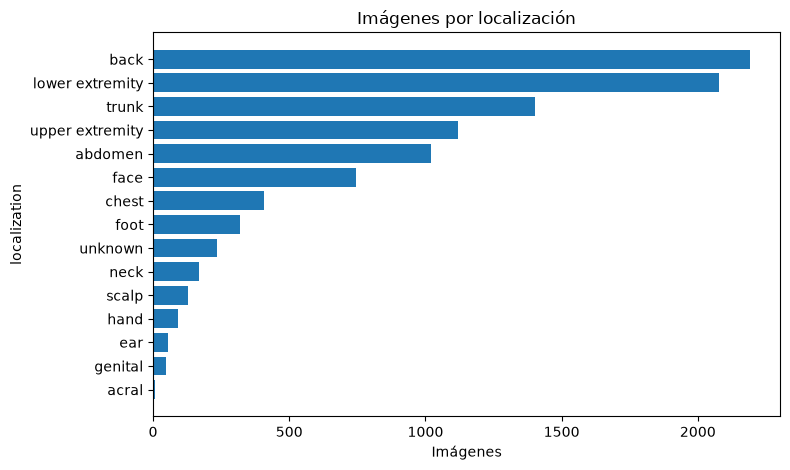

,n,porcentaje
localization,,
back,2192,21.887169
lower extremity,2077,20.738892
trunk,1404,14.018972
upper extremity,1118,11.163255
abdomen,1022,10.204693
face,745,7.438842
chest,407,4.063904
foot,319,3.185222
unknown,234,2.336495


In [24]:
conteo = stats.value_counts_pct(meta["localization"])
eda.plot_counts(conteo, "Imágenes por localización", "localization", horizontal=True)
plt.show()
conteo

#### Fuente de las imágenes

Solo si los metadatos tienen la columna `source_column`.

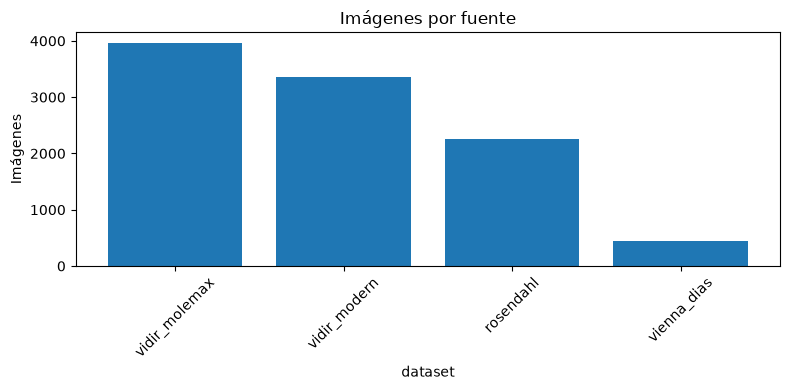

,n,porcentaje
dataset,,
vidir_molemax,3954,39.480779
vidir_modern,3363,33.579631
rosendahl,2259,22.556166
vienna_dias,439,4.383425


In [25]:
if tiene_fuente:
    conteo = stats.value_counts_pct(meta[fuente])
    eda.plot_counts(conteo, "Imágenes por fuente", fuente)
    plt.show()
    display(conteo)
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

#### Método diagnóstico (dx_type)

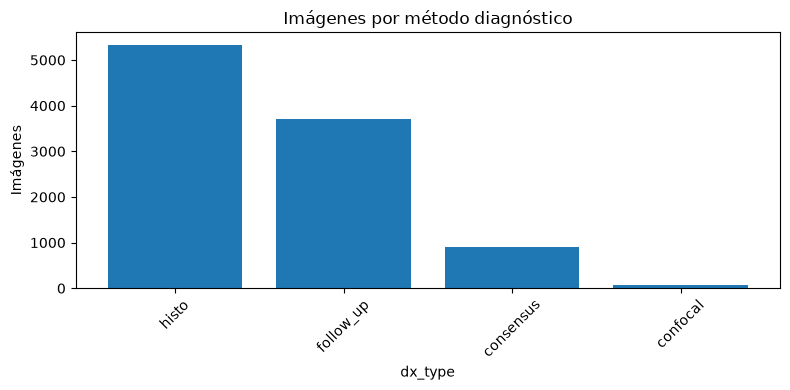

,n,porcentaje
dx_type,,
histo,5340,53.320020
follow_up,3704,36.984523
consensus,902,9.006490
confocal,69,0.688967


In [26]:
conteo = stats.value_counts_pct(meta["dx_type"])
eda.plot_counts(conteo, "Imágenes por método diagnóstico", "dx_type")
plt.show()
conteo

#### Imágenes por lesion_id

In [27]:
por_lesion = meta.groupby("lesion_id").agg(dx=("dx", "first"), n_dx=("dx", "nunique"),
                                           n_imagenes=("image_id", "size"))
display(pd.Series({"lesiones con más de un dx": int((por_lesion["n_dx"] > 1).sum())}, name="valor").to_frame())
stats.value_counts_pct(por_lesion["n_imagenes"]).sort_index()

,valor
lesiones con más de un dx,0


,n,porcentaje
n_imagenes,,
1,5514,73.815261
2,1423,19.049531
3,490,6.559572
4,34,0.455154
5,5,0.066934
6,4,0.053548


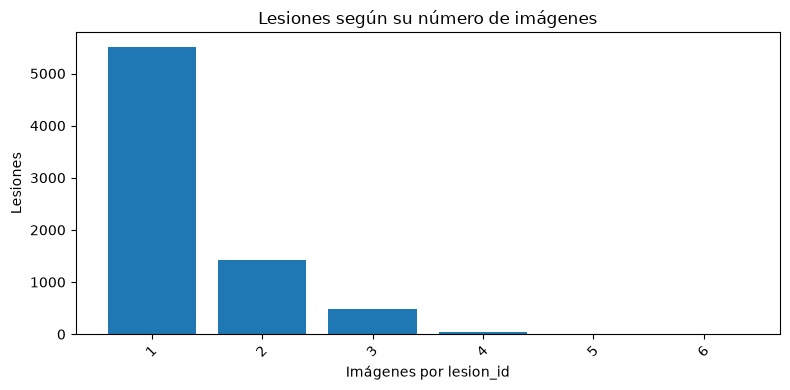

In [28]:
eda.plot_counts(stats.value_counts_pct(por_lesion["n_imagenes"]).sort_index(),
                "Lesiones según su número de imágenes", "Imágenes por lesion_id", value_label="Lesiones")
plt.show()

#### Faltantes

Faltantes por columna, contando como faltantes los valores de `missing_tokens`.

In [29]:
data.missing_summary(meta, cfg["missing_tokens"])

,faltantes,porcentaje
lesion_id,0,0.000000
image_id,0,0.000000
dx,0,0.000000
dx_type,0,0.000000
age,57,0.569146
sex,57,0.569146
localization,234,2.336495
dataset,0,0.000000


#### Mecanismo de los faltantes

Indicador de faltante (vacío o valor de `missing_tokens`) para las columnas de
`missing_indicator_columns`; coincidencia entre indicadores; relación de cada indicador
con `dx` y con la fuente (conteos, porcentajes por fila, chi-cuadrado con p-valor
asintótico y simulado, y V de Cramér); y, con la edad observada, relación del faltante
de `localization` con la edad (Kruskal-Wallis).

In [30]:
cols_falta = cfg["missing_indicator_columns"]
ind_cols = [f"falta_{c}" for c in cols_falta]
ind_falta = eda.missing_indicators(meta, cols_falta, cfg["missing_tokens"], keep=("image_id", "dx", fuente))
ind_falta[ind_cols].sum().rename("faltantes").to_frame()

,faltantes
falta_age,57
falta_sex,57
falta_localization,234


Coincidencia entre los indicadores de faltante.

In [31]:
pd.crosstab([ind_falta[c] for c in ind_cols[:-1]], ind_falta[ind_cols[-1]], margins=True, margins_name="Total")

falta_localization   False  True  Total
falta_age falta_sex                    
False     False       9761   187   9948
          True          10     0     10
True      False         10     0     10
          True           0    47     47
Total                 9781   234  10015

Cada indicador frente a `dx`: conteos y porcentajes por fila.

In [32]:
for c in ind_cols:
    conteos, pct = stats.crosstab_with_pct(ind_falta, "dx", c)
    display(conteos)
    display(pct.round(1))

falta_age,False,True,Total
dx,,,
akiec,327,0,327
bcc,514,0,514
bkl,1089,10,1099
df,115,0,115
mel,1111,2,1113
nv,6660,45,6705
vasc,142,0,142
Total,9958,57,10015


falta_age,False,True
dx,,
akiec,100.0,0.0
bcc,100.0,0.0
bkl,99.1,0.9
df,100.0,0.0
mel,99.8,0.2
nv,99.3,0.7
vasc,100.0,0.0


falta_sex,False,True,Total
dx,,,
akiec,327,0,327
bcc,514,0,514
bkl,1089,10,1099
df,115,0,115
mel,1113,0,1113
nv,6658,47,6705
vasc,142,0,142
Total,9958,57,10015


falta_sex,False,True
dx,,
akiec,100.0,0.0
bcc,100.0,0.0
bkl,99.1,0.9
df,100.0,0.0
mel,100.0,0.0
nv,99.3,0.7
vasc,100.0,0.0


falta_localization,False,True,Total
dx,,,
akiec,327,0,327
bcc,509,5,514
bkl,1076,23,1099
df,115,0,115
mel,1103,10,1113
nv,6509,196,6705
vasc,142,0,142
Total,9781,234,10015


falta_localization,False,True
dx,,
akiec,100.0,0.0
bcc,99.0,1.0
bkl,97.9,2.1
df,100.0,0.0
mel,99.1,0.9
nv,97.1,2.9
vasc,100.0,0.0


Cada indicador frente a la fuente: conteos y porcentajes por fila.

In [33]:
if tiene_fuente:
    for c in ind_cols:
        conteos, pct = stats.crosstab_with_pct(ind_falta, fuente, c)
        display(conteos)
        display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

falta_age,False,True,Total
dataset,,,
rosendahl,2257,2,2259
vidir_modern,3310,53,3363
vidir_molemax,3952,2,3954
vienna_dias,439,0,439
Total,9958,57,10015


falta_age,False,True
dataset,,
rosendahl,99.9,0.1
vidir_modern,98.4,1.6
vidir_molemax,99.9,0.1
vienna_dias,100.0,0.0


falta_sex,False,True,Total
dataset,,,
rosendahl,2259,0,2259
vidir_modern,3306,57,3363
vidir_molemax,3954,0,3954
vienna_dias,439,0,439
Total,9958,57,10015


falta_sex,False,True
dataset,,
rosendahl,100.0,0.0
vidir_modern,98.3,1.7
vidir_molemax,100.0,0.0
vienna_dias,100.0,0.0


falta_localization,False,True,Total
dataset,,,
rosendahl,2246,13,2259
vidir_modern,3156,207,3363
vidir_molemax,3944,10,3954
vienna_dias,435,4,439
Total,9781,234,10015


falta_localization,False,True
dataset,,
rosendahl,99.4,0.6
vidir_modern,93.8,6.2
vidir_molemax,99.7,0.3
vienna_dias,99.1,0.9


Chi-cuadrado y V de Cramér de cada indicador frente a `dx` y frente a la fuente.

In [34]:
objetivos_falta = ["dx"] + ([fuente] if tiene_fuente else [])
pd.concat({obj: stats.chi2_table(ind_falta, ind_cols, obj, n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"]) for obj in objetivos_falta},
          names=["frente a", "indicador"])

chi2   gl  p_asintotico  p_simulado  \
frente a indicador                                                       
dx       falta_age            12.755761  6.0  4.708267e-02    0.058994   
         falta_sex            16.969937  6.0  9.394369e-03    0.023098   
         falta_localization   38.647074  6.0  8.392924e-07    0.000200   
dataset  falta_age            90.763160  3.0  1.501874e-19    0.000100   
         falta_sex           113.391124  3.0  2.043810e-24    0.000100   
         falta_localization  324.748781  3.0  4.372635e-70    0.000100   

                             v_cramer        n  prop_esperadas_lt5  \
frente a indicador                                                   
dx       falta_age           0.035688  10015.0            0.285714   
         falta_sex           0.041164  10015.0            0.285714   
         falta_localization  0.062120  10015.0            0.142857   
dataset  falta_age           0.095198  10015.0            0.125000   
         falta_sex           0.106405  10015.0            0.125000   
         falta_localization  0.180073  10015.0            0.000000   

                             iteraciones_mc  
frente a indicador                           
dx       falta_age                  10000.0  
         falta_sex                  10000.0  
         falta_localization         10000.0  
dataset  falta_age                  10000.0  
         falta_sex                  10000.0  
         falta_localization         10000.0

Edad según el faltante de `localization` (solo filas con edad observada), con Kruskal-Wallis.

In [35]:
if "age" in cols_falta and "localization" in cols_falta:
    display(meta_na.groupby(ind_falta["falta_localization"])["age"].describe())
    display(pd.Series(stats.kruskal_epsilon2(meta_na["age"], ind_falta["falta_localization"]),
                      name="edad ~ falta_localization").to_frame())
else:
    display(pd.DataFrame({"aviso": ["age o localization no están en missing_indicator_columns."]}))

,count,mean,std,min,25%,50%,75%,max
falta_localization,,,,,,,,
False,9771.0,51.983932,16.974653,0.0,40.0,50.0,65.0,85.0
True,187.0,45.588235,15.438970,10.0,40.0,40.0,55.0,85.0


,edad ~ falta_localization
H,3.673973e+01
gl,1.000000e+00
p,1.349998e-09
epsilon2,3.689839e-03
n,9.958000e+03
k,2.000000e+00


### 4.B Bivariado frente a dx

Relación de cada variable con la clase `dx`.

#### Edad, sexo y localización por clase

Kruskal-Wallis con ε² para la edad; chi-cuadrado (p-valor asintótico y simulado) y V de
Cramér para sexo y localización. Se excluyen los faltantes.

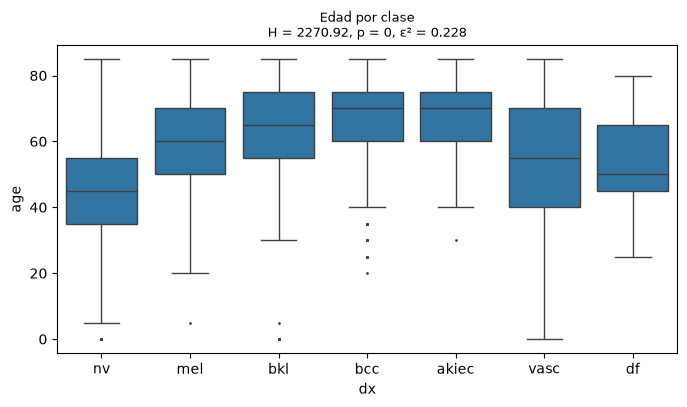

,edad
H,2270.922177
gl,6.000000
p,0.000000
epsilon2,0.228073
n,9958.000000
k,7.000000


In [36]:
res_edad = stats.kruskal_epsilon2(meta_na["age"], meta_na["dx"])
eda.boxplot_by_class(meta_na, "age", "dx", order=orden_dx, title="Edad por clase", test=res_edad)
plt.show()
pd.Series(res_edad, name="edad").to_frame()

In [37]:
conteos, pct = stats.crosstab_with_pct(meta_na, "sex", "dx")
display(conteos)
pct.round(1)

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
sex,,,,,,,,
female,106,197,463,52,424,3237,73,4552
male,221,317,626,63,689,3421,69,5406
Total,327,514,1089,115,1113,6658,142,9958


dx,akiec,bcc,bkl,df,mel,nv,vasc
sex,,,,,,,
female,2.3,4.3,10.2,1.1,9.3,71.1,1.6
male,4.1,5.9,11.6,1.2,12.7,63.3,1.3


In [38]:
conteos, pct = stats.crosstab_with_pct(meta_na, "localization", "dx")
display(conteos)
pct.round(1)

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
localization,,,,,,,,
abdomen,5,18,42,4,66,860,27,1022
acral,0,0,0,0,0,7,0,7
back,29,186,202,2,324,1427,22,2192
chest,12,47,74,0,68,200,6,407
ear,3,0,6,0,17,30,0,56
face,113,101,319,0,104,100,8,745
foot,0,4,1,2,28,284,0,319
genital,0,0,2,1,0,45,0,48
hand,13,2,14,0,1,55,5,90


dx,akiec,bcc,bkl,df,mel,nv,vasc
localization,,,,,,,
abdomen,0.5,1.8,4.1,0.4,6.5,84.1,2.6
acral,0.0,0.0,0.0,0.0,0.0,100.0,0.0
back,1.3,8.5,9.2,0.1,14.8,65.1,1.0
chest,2.9,11.5,18.2,0.0,16.7,49.1,1.5
ear,5.4,0.0,10.7,0.0,30.4,53.6,0.0
face,15.2,13.6,42.8,0.0,14.0,13.4,1.1
foot,0.0,1.3,0.3,0.6,8.8,89.0,0.0
genital,0.0,0.0,4.2,2.1,0.0,93.8,0.0
hand,14.4,2.2,15.6,0.0,1.1,61.1,5.6


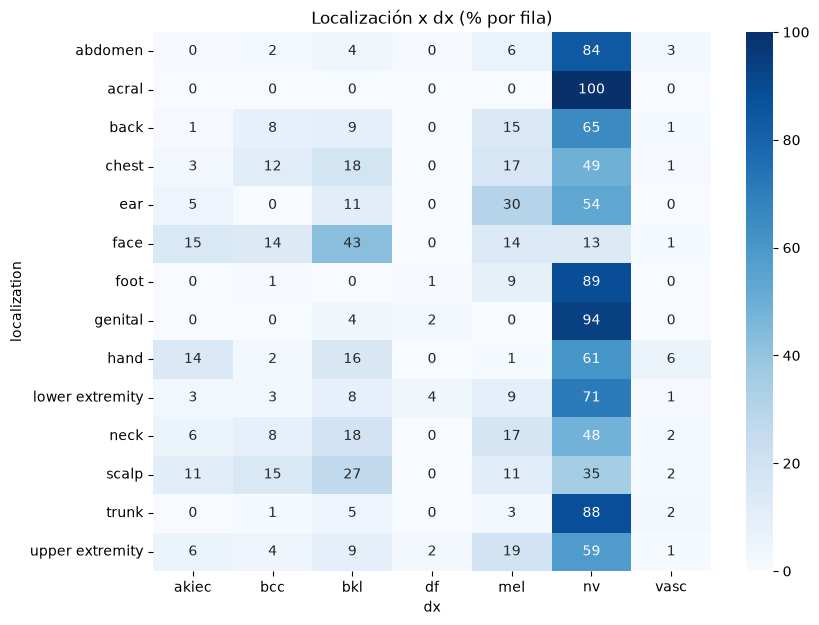

In [39]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_title("Localización x dx (% por fila)")
plt.show()

In [40]:
stats.chi2_table(meta_na, ["sex", "localization"], "dx", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"])

,chi2,gl,p_asintotico,p_simulado,v_cramer,n,prop_esperadas_lt5,iteraciones_mc
sex,89.621646,6.0,3.630947e-17,0.0001,0.094868,9958.0,0.00000,10000.0
localization,2758.541032,78.0,0.000000e+00,0.0001,0.216807,9781.0,0.27551,10000.0


#### Fuente de las imágenes por clase

Solo si los metadatos tienen la columna `source_column`.

In [41]:
if tiene_fuente:
    conteos, pct = stats.crosstab_with_pct(meta_na, fuente, "dx")
    display(conteos)
    display(pct.round(1))
    display(pd.Series(stats.chi2_from_columns(meta_na, fuente, "dx", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"]), name=fuente).to_frame())
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
dataset,,,,,,,,
rosendahl,295,296,490,30,342,803,3,2259
vidir_modern,32,211,475,51,680,1832,82,3363
vidir_molemax,0,2,124,30,24,3720,54,3954
vienna_dias,0,5,10,4,67,350,3,439
Total,327,514,1099,115,1113,6705,142,10015


dx,akiec,bcc,bkl,df,mel,nv,vasc
dataset,,,,,,,
rosendahl,13.1,13.1,21.7,1.3,15.1,35.5,0.1
vidir_modern,1.0,6.3,14.1,1.5,20.2,54.5,2.4
vidir_molemax,0.0,0.1,3.1,0.8,0.6,94.1,1.4
vienna_dias,0.0,1.1,2.3,0.9,15.3,79.7,0.7


,dataset
chi2,3484.061981
gl,18.000000
p_asintotico,0.000000
p_simulado,0.000100
v_cramer,0.340531
n,10015.000000
prop_esperadas_lt5,0.000000
iteraciones_mc,10000.000000


#### Método diagnóstico (dx_type) por clase

In [42]:
conteos, pct = stats.crosstab_with_pct(meta, "dx_type", "dx")
display(conteos)
pct.round(1)

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
dx_type,,,,,,,,
confocal,0,0,69,0,0,0,0,69
consensus,0,0,264,60,0,503,75,902
follow_up,0,0,0,0,0,3704,0,3704
histo,327,514,766,55,1113,2498,67,5340
Total,327,514,1099,115,1113,6705,142,10015


dx,akiec,bcc,bkl,df,mel,nv,vasc
dx_type,,,,,,,
confocal,0.0,0.0,100.0,0.0,0.0,0.0,0.0
consensus,0.0,0.0,29.3,6.7,0.0,55.8,8.3
follow_up,0.0,0.0,0.0,0.0,0.0,100.0,0.0
histo,6.1,9.6,14.3,1.0,20.8,46.8,1.3


#### Imágenes por lesion_id por clase

In [43]:
pd.crosstab(por_lesion["dx"], por_lesion["n_imagenes"], margins=True, margins_name="Total")

n_imagenes,1,2,3,4,5,6,Total
dx,,,,,,,
akiec,151,57,18,2,0,0,228
bcc,175,118,33,1,0,0,327
bkl,440,220,55,8,2,2,727
df,39,26,8,0,0,0,73
mel,230,278,100,4,1,1,614
nv,4415,699,268,18,2,1,5403
vasc,64,25,8,1,0,0,98
Total,5514,1423,490,34,5,4,7470


In [44]:
por_lesion.groupby("dx")["n_imagenes"].agg(["count", "mean", "median", "max"]).loc[orden_dx]

,count,mean,median,max
dx,,,,
nv,5403,1.240977,1.0,6
mel,614,1.812704,2.0,6
bkl,727,1.511692,1.0,6
bcc,327,1.571865,1.0,4
akiec,228,1.434211,1.0,4
vasc,98,1.448980,1.0,4
df,73,1.575342,1.0,3


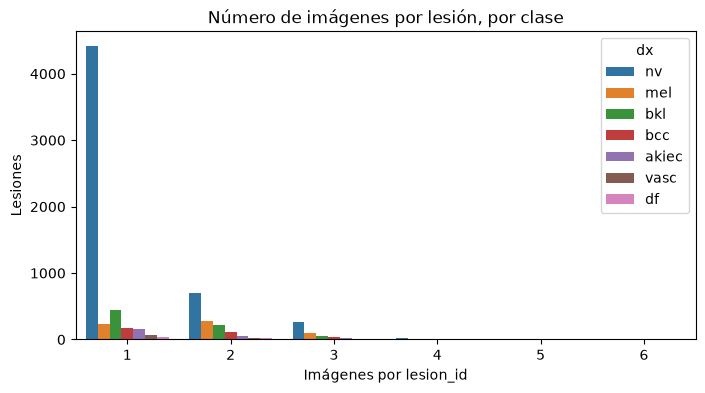

In [45]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=por_lesion, x="n_imagenes", hue="dx", hue_order=orden_dx, ax=ax)
ax.set_title("Número de imágenes por lesión, por clase")
ax.set_xlabel("Imágenes por lesion_id")
ax.set_ylabel("Lesiones")
plt.show()

#### Información mutua con dx

`mutual_info_classif` (scikit-learn, semilla `seed`) entre `dx` y cada variable: las
categóricas como discretas, con los faltantes como categoría propia; la edad como
continua, sin las filas con edad faltante. Resultado en nats y en bits, ordenado de mayor
a menor.

In [46]:
cat_mi = ["sex", "localization", "dx_type", *([fuente] if tiene_fuente else [])]
mi_dx = stats.mutual_info_table(meta_na, "dx", cat_mi, ["age"], cfg["seed"])
mi_dx

,tipo,n,categorias,mi_nats,mi_bits
variable,,,,,
dx_type,categórica,10015,4,0.256416,0.369930
dataset,categórica,10015,4,0.189563,0.273481
age,continua,9958,NaN,0.135700,0.195774
localization,categórica,10015,15,0.131515,0.189736
sex,categórica,10015,3,0.005980,0.008627


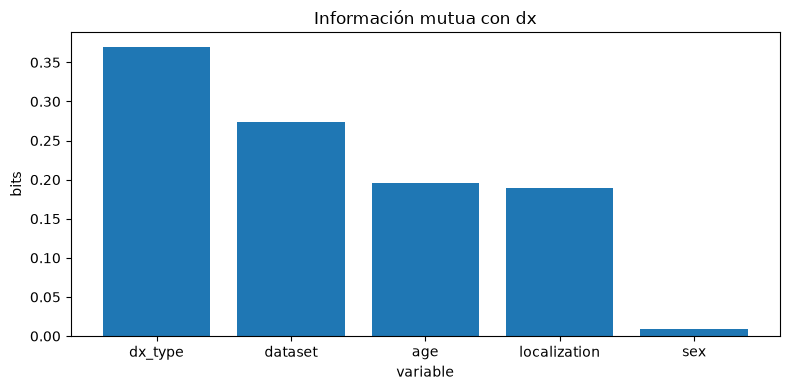

In [47]:
eda.plot_bar_values(mi_dx["mi_bits"], "Información mutua con dx", "variable", "bits")
plt.show()

### 4.C Bivariado entre covariables

Fuente frente a `dx_type`, `localization` y `sex` (conteos y porcentajes por fila,
chi-cuadrado con p-valor asintótico y simulado, y V de Cramér), y edad por fuente
(Kruskal-Wallis y ε²). Solo si los metadatos tienen la columna `source_column`. Se
excluyen los faltantes.

#### Fuente x dx_type

In [48]:
if tiene_fuente:
    conteos, pct = stats.crosstab_with_pct(meta_na, fuente, "dx_type")
    display(conteos)
    display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

dx_type,confocal,consensus,follow_up,histo,Total
dataset,,,,,
rosendahl,0,0,0,2259,2259
vidir_modern,69,700,0,2594,3363
vidir_molemax,0,202,3704,48,3954
vienna_dias,0,0,0,439,439
Total,69,902,3704,5340,10015


dx_type,confocal,consensus,follow_up,histo
dataset,,,,
rosendahl,0.0,0.0,0.0,100.0
vidir_modern,2.1,20.8,0.0,77.1
vidir_molemax,0.0,5.1,93.7,1.2
vienna_dias,0.0,0.0,0.0,100.0


#### Fuente x localización

In [49]:
if tiene_fuente:
    conteos, pct = stats.crosstab_with_pct(meta_na, fuente, "localization")
    display(conteos)
    display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

localization,abdomen,acral,back,chest,ear,face,foot,genital,hand,lower extremity,neck,scalp,trunk,upper extremity,Total
dataset,,,,,,,,,,,,,,,
rosendahl,78,0,681,166,17,320,58,3,34,433,64,53,5,334,2246
vidir_modern,276,6,820,193,36,390,126,6,29,535,68,69,207,395,3156
vidir_molemax,619,0,580,9,3,29,117,39,24,1014,32,6,1131,341,3944
vienna_dias,49,1,111,39,0,6,18,0,3,95,4,0,61,48,435
Total,1022,7,2192,407,56,745,319,48,90,2077,168,128,1404,1118,9781


localization,abdomen,acral,back,chest,ear,face,foot,genital,hand,lower extremity,neck,scalp,trunk,upper extremity
dataset,,,,,,,,,,,,,,
rosendahl,3.5,0.0,30.3,7.4,0.8,14.2,2.6,0.1,1.5,19.3,2.8,2.4,0.2,14.9
vidir_modern,8.7,0.2,26.0,6.1,1.1,12.4,4.0,0.2,0.9,17.0,2.2,2.2,6.6,12.5
vidir_molemax,15.7,0.0,14.7,0.2,0.1,0.7,3.0,1.0,0.6,25.7,0.8,0.2,28.7,8.6
vienna_dias,11.3,0.2,25.5,9.0,0.0,1.4,4.1,0.0,0.7,21.8,0.9,0.0,14.0,11.0


#### Fuente x sexo

In [50]:
if tiene_fuente:
    conteos, pct = stats.crosstab_with_pct(meta_na, fuente, "sex")
    display(conteos)
    display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

sex,female,male,Total
dataset,,,
rosendahl,902,1357,2259
vidir_modern,1515,1791,3306
vidir_molemax,1912,2042,3954
vienna_dias,223,216,439
Total,4552,5406,9958


sex,female,male
dataset,,
rosendahl,39.9,60.1
vidir_modern,45.8,54.2
vidir_molemax,48.4,51.6
vienna_dias,50.8,49.2


#### Chi-cuadrado y V de Cramér

In [51]:
if tiene_fuente:
    display(stats.chi2_table(meta_na, ["dx_type", "localization", "sex"], fuente, n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"]))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

,chi2,gl,p_asintotico,p_simulado,v_cramer,n,prop_esperadas_lt5,iteraciones_mc
dx_type,10118.224748,9.0,0.000000e+00,0.0001,0.580318,10015.0,0.0625,10000.0
localization,2514.534932,39.0,0.000000e+00,0.0001,0.292736,9781.0,0.1250,10000.0
sex,46.172430,3.0,5.212348e-10,0.0001,0.068093,9958.0,0.0000,10000.0


#### Edad por fuente

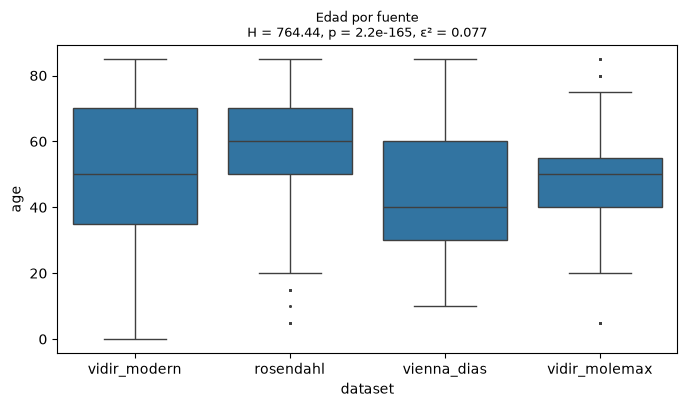

,edad
H,7.644369e+02
gl,3.000000e+00
p,2.232603e-165
epsilon2,7.677382e-02
n,9.958000e+03
k,4.000000e+00


In [52]:
if tiene_fuente:
    res_edad_fuente = stats.kruskal_epsilon2(meta_na["age"], meta_na[fuente])
    eda.boxplot_by_class(meta_na, "age", fuente, title="Edad por fuente", test=res_edad_fuente)
    plt.show()
    display(pd.Series(res_edad_fuente, name="edad").to_frame())
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

### 4.D Atributos con fuga

`dx_type` y la fuente frente a `dx`: V de Cramér (con el chi-cuadrado, p-valor asintótico y
simulado), información mutua (de 4.B) y pureza de cada categoría (porcentaje de la clase
mayoritaria y la clase correspondiente).

In [53]:
cols_fuga = ["dx_type", *([fuente] if tiene_fuente else [])]
chi_fuga = stats.chi2_table(meta_na, cols_fuga, "dx", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"])
chi_fuga[["v_cramer", "p_asintotico", "p_simulado", "prop_esperadas_lt5"]].join(mi_dx[["mi_nats", "mi_bits"]])

,v_cramer,p_asintotico,p_simulado,prop_esperadas_lt5,mi_nats,mi_bits
dx_type,0.390297,0.0,0.0001,0.142857,0.256416,0.369930
dataset,0.340531,0.0,0.0001,0.000000,0.189563,0.273481


In [54]:
stats.purity_table(meta_na, cols_fuga, "dx")

n clase_mayoritaria  pct_mayoritaria
variable categoria                                             
dx_type  confocal         69               bkl       100.000000
         consensus       902                nv        55.764967
         follow_up      3704                nv       100.000000
         histo          5340                nv        46.779026
dataset  rosendahl      2259                nv        35.546702
         vidir_modern   3363                nv        54.475171
         vidir_molemax  3954                nv        94.081942
         vienna_dias     439                nv        79.726651

#### Ruido de etiquetas: método diagnóstico

Porcentaje de imágenes y de lesiones por `dx_type` (en el orden de
`valid_categories.dx_type`), global y por clase. A nivel de lesión se usa el primer
`dx_type` de cada lesión; se informa cuántas lesiones tienen más de un valor.

In [55]:
tipos = stats.type_shares(meta, "dx_type", "dx", "lesion_id", cfg["valid_categories"]["dx_type"], orden_dx)
display(pd.Series({"lesiones con más de un dx_type": tipos["lesiones_con_mas_de_un_tipo"]}, name="valor").to_frame())
pd.concat({"imágenes": tipos["imagenes_global"], "lesiones": tipos["lesiones_global"]}, axis=1)

,valor
lesiones con más de un dx_type,0


imágenes            lesiones           
                 n porcentaje        n porcentaje
dx_type                                          
histo         5340  53.320020     3085  41.298527
follow_up     3704  36.984523     3704  49.585007
consensus      902   9.006490      647   8.661312
confocal        69   0.688967       34   0.455154

Porcentaje de imágenes por `dx_type` dentro de cada clase.

In [56]:
tipos["imagenes_por_clase"].round(1)

dx_type,histo,follow_up,consensus,confocal
dx,,,,
nv,37.3,55.2,7.5,0.0
mel,100.0,0.0,0.0,0.0
bkl,69.7,0.0,24.0,6.3
bcc,100.0,0.0,0.0,0.0
akiec,100.0,0.0,0.0,0.0
vasc,47.2,0.0,52.8,0.0
df,47.8,0.0,52.2,0.0


Porcentaje de lesiones por `dx_type` dentro de cada clase.

In [57]:
tipos["lesiones_por_clase"].round(1)

dx_type,histo,follow_up,consensus,confocal
dx,,,,
nv,25.3,68.6,6.1,0.0
mel,100.0,0.0,0.0,0.0
bkl,67.0,0.0,28.3,4.7
bcc,100.0,0.0,0.0,0.0
akiec,100.0,0.0,0.0,0.0
vasc,33.7,0.0,66.3,0.0
df,39.7,0.0,60.3,0.0


## 5. Partición

`group_id` une las imágenes de un mismo `lesion_id` y los pares confirmados. Test se
obtiene con `StratifiedGroupKFold` (estrato `dx`, grupo `group_id`) con el número de
pliegues cuya proporción es la más cercana a `test_size`; el primer pliegue es test. El
resto se reparte en `n_folds` pliegues con el mismo método.

In [58]:
group_id = data.build_groups(meta, confirmados)
display(pd.Series({"lesion_id": meta["lesion_id"].nunique(), "group_id": group_id.nunique()},
                  name="valores únicos").to_frame())
group_id.value_counts().value_counts().sort_index().rename("grupos por tamaño").to_frame()

,valores únicos
lesion_id,7470
group_id,7470


,grupos por tamaño
count,
1,5514
2,1423
3,490
4,34
5,5
6,4


In [59]:
k_test = data.closest_n_splits(cfg["test_size"])
pd.Series({"pliegues para test": k_test, "proporción esperada (1 / pliegues)": round(1 / k_test, 3)},
          name="valor").to_frame()

,valor
pliegues para test,7.000
proporción esperada (1 / pliegues),0.143


Si `data/splits.csv` ya existe y `overwrite_splits` es `false`, se carga en lugar de
generarse.

In [60]:
ruta_splits = rutas["splits_csv"]
if ruta_splits.exists() and not cfg["overwrite_splits"]:
    splits = data.load_splits(ruta_splits)
    origen_splits = "existente, cargada"
else:
    splits = data.make_splits(meta, group_id, cfg["test_size"], cfg["n_folds"], cfg["seed"])
    data.save_splits(splits, ruta_splits)
    origen_splits = "generada y guardada"
display(pd.Series({"partición": origen_splits, "archivo": str(ruta_splits)}, name="valor").to_frame())
splits.head()

,valor
partición,"existente, cargada"
archivo,/var/home/luencaro/Programing/College/2026-30/...


,image_id,lesion_id,group_id,dx,split,fold
0,ISIC_0027419,HAM_0000118,HAM_0000118,bkl,train,1
1,ISIC_0025030,HAM_0000118,HAM_0000118,bkl,train,1
2,ISIC_0026769,HAM_0002730,HAM_0002730,bkl,train,0
3,ISIC_0025661,HAM_0002730,HAM_0002730,bkl,train,0
4,ISIC_0031633,HAM_0001466,HAM_0001466,bkl,train,3


Comprobaciones de la partición.

In [61]:
assert splits["image_id"].is_unique, "Hay imágenes repetidas"
assert splits.groupby("group_id")["split"].nunique().max() == 1, "Un group_id está en train y en test"
entreno = splits[splits["split"] == "train"]
assert entreno.groupby("group_id")["fold"].nunique().max() == 1, "Un group_id está en dos pliegues"
data.validate_splits(splits, cfg["n_folds"])
data.check_splits_match(splits, meta, group_id)
pd.Series({"comprobaciones de la partición": "superadas"}, name="resultado").to_frame()

,resultado
comprobaciones de la partición,superadas


Distribución de clases por partición.

In [62]:
conteos, pct = stats.crosstab_with_pct(splits, "split", "dx")
display(conteos)
pct.round(1)

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
split,,,,,,,,
test,46,74,157,17,159,958,20,1431
train,281,440,942,98,954,5747,122,8584
Total,327,514,1099,115,1113,6705,142,10015


dx,akiec,bcc,bkl,df,mel,nv,vasc
split,,,,,,,
test,3.2,5.2,11.0,1.2,11.1,66.9,1.4
train,3.3,5.1,11.0,1.1,11.1,67.0,1.4


Distribución de fuentes por partición.

In [63]:
if tiene_fuente:
    splits_fuente = splits.merge(meta[["image_id", fuente]], on="image_id")
    conteos, pct = stats.crosstab_with_pct(splits_fuente, "split", fuente)
    display(conteos)
    display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias,Total
split,,,,,
test,330,455,567,79,1431
train,1929,2908,3387,360,8584
Total,2259,3363,3954,439,10015


dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias
split,,,,
test,23.1,31.8,39.6,5.5
train,22.5,33.9,39.5,4.2


Distribución de clases por pliegue (solo train).

In [64]:
entreno = splits[splits["split"] == "train"]

In [65]:
conteos, pct = stats.crosstab_with_pct(entreno, "fold", "dx")
display(conteos)
pct.round(1)

dx,akiec,bcc,bkl,df,mel,nv,vasc,Total
fold,,,,,,,,
0,56,88,188,20,191,1150,24,1717
1,56,88,188,20,191,1149,25,1717
2,56,88,188,20,191,1149,25,1717
3,57,88,189,19,191,1149,24,1717
4,56,88,189,19,190,1150,24,1716
Total,281,440,942,98,954,5747,122,8584


dx,akiec,bcc,bkl,df,mel,nv,vasc
fold,,,,,,,
0,3.3,5.1,10.9,1.2,11.1,67.0,1.4
1,3.3,5.1,10.9,1.2,11.1,66.9,1.5
2,3.3,5.1,10.9,1.2,11.1,66.9,1.5
3,3.3,5.1,11.0,1.1,11.1,66.9,1.4
4,3.3,5.1,11.0,1.1,11.1,67.0,1.4


Distribución de fuentes por pliegue (solo train).

In [66]:
if tiene_fuente:
    entreno_fuente = entreno.merge(meta[["image_id", fuente]], on="image_id")
    conteos, pct = stats.crosstab_with_pct(entreno_fuente, "fold", fuente)
    display(conteos)
    display(pct.round(1))
else:
    display(pd.DataFrame({"aviso": [f"Los metadatos no tienen la columna '{fuente}'."]}))

dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias,Total
fold,,,,,
0,395,582,679,61,1717
1,416,539,677,85,1717
2,392,567,686,72,1717
3,399,586,655,77,1717
4,327,634,690,65,1716
Total,1929,2908,3387,360,8584


dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias
fold,,,,
0,23.0,33.9,39.5,3.6
1,24.2,31.4,39.4,5.0
2,22.8,33.0,40.0,4.2
3,23.2,34.1,38.1,4.5
4,19.1,36.9,40.2,3.8


### Consistencia de covariables entre particiones

Edad por partición y por pliegue (descriptivos, Kolmogorov-Smirnov y diferencia de
medias estandarizada, DME = (media_a − media_b) / √((s²_a + s²_b) / 2)); sexo y
localización por partición y por pliegue (porcentajes por fila, chi-cuadrado con
p-valor asintótico y simulado, y V de Cramér). Se excluyen los faltantes.

In [67]:
cov = splits.merge(meta_na[["image_id", "age", "sex", "localization"]], on="image_id")
cov_train = cov[cov["split"] == "train"]
cov.groupby("split")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,1426.0,51.893408,16.327521,0.0,40.0,50.0,65.0,85.0
train,8532.0,51.858884,17.074338,0.0,40.0,50.0,65.0,85.0


In [68]:
pd.Series(stats.two_sample_compare(cov.loc[cov["split"] == "train", "age"], cov.loc[cov["split"] == "test", "age"]),
          name="edad: train (a) frente a test (b)").to_frame()

,edad: train (a) frente a test (b)
n_a,8532.000000
n_b,1426.000000
media_a,51.858884
media_b,51.893408
ks,0.018940
p_ks,0.764623
dme,-0.002067


In [69]:
for var in ["sex", "localization"]:
    display(stats.crosstab_with_pct(cov, "split", var)[1].round(1))

sex,female,male
split,,
test,47.1,52.9
train,45.5,54.5


localization,abdomen,acral,back,chest,ear,face,foot,genital,hand,lower extremity,neck,scalp,trunk,upper extremity
split,,,,,,,,,,,,,,
test,10.5,0.2,23.1,3.7,0.6,6.0,4.2,0.6,1.1,22.2,1.5,0.9,14.1,11.2
train,10.4,0.0,22.3,4.2,0.6,7.9,3.1,0.5,0.9,21.1,1.8,1.4,14.4,11.5


In [70]:
stats.chi2_table(cov, ["sex", "localization"], "split", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"])

,chi2,gl,p_asintotico,p_simulado,v_cramer,n,prop_esperadas_lt5,iteraciones_mc
sex,1.218554,1.0,0.269645,0.268073,0.011062,9958.0,0.000000,10000.0
localization,21.433111,13.0,0.064792,0.062694,0.046811,9781.0,0.035714,10000.0


Lo mismo por pliegue dentro de train; cada pliegue (a) se compara con el resto de train (b).

In [71]:
cov_train.groupby("fold")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
fold,,,,,,,,
0,1705.0,52.316716,16.985201,0.0,40.0,50.0,65.0,85.0
1,1708.0,52.014052,16.961165,0.0,40.0,50.0,65.0,85.0
2,1705.0,52.486804,17.086942,0.0,40.0,50.0,65.0,85.0
3,1709.0,51.623757,16.306654,0.0,40.0,50.0,65.0,85.0
4,1705.0,50.853372,17.963077,0.0,40.0,50.0,65.0,85.0


In [72]:
stats.compare_groups_vs_rest(cov_train, "age", "fold")

,n_a,n_b,media_a,media_b,ks,p_ks,dme
fold (frente al resto),,,,,,,
0,1705.0,6827.0,52.316716,51.744544,0.038125,0.036747,0.033577
1,1708.0,6824.0,52.014052,51.820047,0.021857,0.522816,0.011390
2,1705.0,6827.0,52.486804,51.702065,0.028877,0.200659,0.045951
3,1709.0,6823.0,51.623757,51.917778,0.031691,0.125242,-0.017511
4,1705.0,6827.0,50.853372,52.110004,0.031881,0.121750,-0.072182


In [73]:
for var in ["sex", "localization"]:
    display(stats.crosstab_with_pct(cov_train, "fold", var)[1].round(1))

sex,female,male
fold,,
0,47.1,52.9
1,45.7,54.3
2,43.8,56.2
3,46.1,53.9
4,44.8,55.2


localization,abdomen,acral,back,chest,ear,face,foot,genital,hand,lower extremity,neck,scalp,trunk,upper extremity
fold,,,,,,,,,,,,,,
0,9.7,0.1,21.7,4.5,0.4,7.2,2.5,0.5,1.0,22.0,1.9,1.4,14.2,13.0
1,8.2,0.2,24.2,4.5,0.8,8.0,2.4,0.5,0.6,21.0,2.0,1.5,15.1,11.0
2,11.7,0.0,22.0,3.5,0.1,7.9,3.6,0.5,1.0,20.5,1.4,0.9,14.0,13.0
3,10.7,0.0,23.5,3.5,1.3,7.1,3.3,0.2,1.4,21.7,1.1,1.1,13.3,11.7
4,11.8,0.0,20.0,5.1,0.2,9.2,3.8,0.7,0.5,20.2,2.4,1.9,15.4,8.7


In [74]:
stats.chi2_table(cov_train, ["sex", "localization"], "fold", n_iter=cfg["chi2_mc_iterations"], seed=cfg["seed"])

,chi2,gl,p_asintotico,p_simulado,v_cramer,n,prop_esperadas_lt5,iteraciones_mc
sex,4.387626,4.0,3.560808e-01,0.358364,0.022680,8530.0,0.000000,10000.0
localization,136.242039,52.0,1.778139e-09,0.000100,0.063738,8384.0,0.071429,10000.0


SHA-256 de `splits.csv` y de la lista ordenada de `image_id` de test.

In [75]:
hash_splits = data.splits_hashes(ruta_splits, splits)
data.save_json(hash_splits, rutas["splits_hash_json"])
pd.Series(hash_splits, name="valor").to_frame()

,valor
splits_csv_sha256,982e907e9c32b02570f21a0fe404bffa7466f70af605aa...
test_image_ids_sha256,408c8566deeba2c2d45837108ee5ba38103d83903a6d43...
n_train,8584
n_test,1431
